# 합성 marker 자료의 treated-control 탐색

**질문:** 같은 24시간 시점의 서로 다른 기증자에서, treated와 control의 정규화된 marker 값은 얼마나 다른가? 표본 연결, 독립 반복, 배치를 확인한 뒤 차이의 크기와 불확실성, 한 기증자의 영향을 살펴본다.

**입력과 알려진 사실:** `context.md`는 사람 배양 세포의 bulk marker panel을 흉내 낸 **합성 자료**라고 명시한다. `measurements.tsv`의 행은 가상 marker, 열은 `sample_id`, 값은 배경 보정과 표본 간 정규화가 끝난 **log2 intensity**이다. 0은 이 척도의 값이고 NA가 결측이다. `metadata.tsv`는 표본·기증자·조건·배치를 연결한다. 기증자는 독립 단위이고 기술 반복은 없다. 사전 제외 기준은 측정 실패이며, 실패 기록은 없다. 추가 로그 변환, count 모형, 외부 annotation은 적용하지 않는다.

**아직 확인되지 않은 것:** 조건 배정의 무작위성, 보정·정규화 세부 절차, 정규오차·동일분산 가정은 주어진 기록으로 검증되지 않는다. 합성 결과로 실제 생물학이나 인과성을 주장하지 않는다.

**재실행:** 이 노트북을 입력 TSV와 같은 디렉터리에서 열어 위에서부터 실행하거나, 그 디렉터리에서 `python run_analysis.py`를 실행한다. 필요한 패키지는 numpy, pandas, scipy, matplotlib, nbformat, nbclient, ipykernel이다. 환경 설치는 수행하지 않았다. `results/`에는 요약 표와 그림이 저장되며 원본 입력은 수정하지 않는다. 무작위 계산은 없고 그림의 가로 위치 이동도 고정값이다.

분석은 각 단계의 스크립트 출력을 먼저 확인한 뒤 다음 계산을 작성했고, 아래 노트북은 이를 직접 읽을 수 있는 코드로 정리한 것이다. 최종 노트북의 코드 출력은 새 커널에서 실제 실행해 저장한다.

## 1. 표본 ID를 정확히 연결할 수 있는가?

표본 순서에 의존하면 처리군을 잘못 연결할 수 있다. 먼저 전체 ID 집합의 일치, 중복, 결측과 무한값을 확인한다. 표의 수는 일부 미리보기가 아니라 전체 입력에 대한 집계다. 원본 열 이름도 따로 읽어 TSV 파서의 중복 이름 변경을 놓치지 않는다.

In [1]:
from pathlib import Path
import hashlib
import csv
import numpy as np
import pandas as pd

root = Path.cwd()
input_names = ['context.md', 'metadata.tsv', 'measurements.tsv']
input_hashes = {name: hashlib.sha256((root / name).read_bytes()).hexdigest() for name in input_names}
metadata = pd.read_csv(root / 'metadata.tsv', sep='\t')
with (root / 'measurements.tsv').open() as handle:
    raw_header = next(csv.reader(handle, delimiter='\t'))
measurements = pd.read_csv(root / 'measurements.tsv', sep='\t', index_col='feature_id')
raw_samples = pd.Index(raw_header[1:])
matched = set(metadata.sample_id) & set(raw_samples)

(root / 'results').mkdir(exist_ok=True)


In [2]:
checks = pd.Series({
    'metadata_samples': len(metadata), 'measurement_samples': len(raw_samples),
    'matched_samples': len(matched), 'metadata_duplicate_ids': int(metadata.sample_id.duplicated().sum()),
    'measurement_duplicate_ids': int(raw_samples.duplicated().sum()),
    'metadata_only_samples': len(set(metadata.sample_id) - set(raw_samples)),
    'measurement_only_samples': len(set(raw_samples) - set(metadata.sample_id)),
    'features': len(measurements), 'duplicate_features': int(measurements.index.duplicated().sum()),
    'missing_values': int(measurements.isna().sum().sum()),
    'infinite_values': int(np.isinf(measurements.to_numpy(dtype=float)).sum()),
    'missing_metadata_entries': int(metadata.isna().sum().sum()),
}, name='count')
print('표본 연결과 값의 완전성을 전체 입력에서 확인합니다. 일치 수는 고유 sample_id 기준입니다.')
print(checks.to_string())
assert metadata.sample_id.is_unique and raw_samples.is_unique, '중복 표본 ID: 연결을 중단합니다.'
assert set(metadata.sample_id) == set(raw_samples), '표본 ID 불일치: 연결을 중단합니다.'
assert measurements.index.is_unique, '중복 marker ID가 있습니다.'
assert not metadata.isna().any().any(), '설계 메타데이터에 결측이 있습니다.'
assert np.isfinite(measurements.to_numpy(dtype=float)).all(), '비유한 측정값을 먼저 검토해야 합니다.'
assert set(metadata.condition) == {'control', 'treated'}, '예상과 다른 조건이 있습니다.'
assert set(metadata.batch) == {'A', 'B'}, '예상과 다른 배치가 있습니다.'


표본 연결과 값의 완전성을 전체 입력에서 확인합니다. 일치 수는 고유 sample_id 기준입니다.
metadata_samples             8
measurement_samples          8
matched_samples              8
metadata_duplicate_ids       0
measurement_duplicate_ids    0
metadata_only_samples        0
measurement_only_samples     0
features                     3
duplicate_features           0
missing_values               0
infinite_values              0
missing_metadata_entries     0


**관찰과 결정:** 두 파일의 8개 표본 ID가 모두 일치한다. 표본·marker ID 중복, 연결되지 않은 ID, 측정값·메타데이터 결측, 무한값은 모두 0이다. 3개 marker × 8개 표본의 24개 값을 유지한다. 필터링·제외·재정규화·추가 로그 변환·대치는 하지 않는다. 이 확인은 연결의 정확성을 지지하며 측정 품질이나 생물학적 타당성을 입증하지 않는다. 다음으로 독립 기증자 수와 조건·배치 구성을 확인한다.

## 2. 독립 반복이 있고 조건과 배치를 구분할 수 있는가?

독립 n은 측정 행 수가 아니라 `donor_id` 수이다. 같은 기증자가 양 조건에 반복되는지 확인하고, 조건×배치 표에서 각 배치에 두 조건이 모두 있는지 본다. 마지막 표는 실제 사용한 ID 연결이며, 모형의 기준은 control과 배치 A이다. 설계행렬 rank가 열 수와 같으면 이 모형에서 조건과 배치 계수를 각각 추정할 수 있다.

In [3]:
metadata = metadata.set_index('sample_id').loc[raw_samples].reset_index().rename(columns={'index': 'sample_id'})
measurements = measurements.loc[:, metadata.sample_id]
print('\n독립 기증자 수를 확인합니다. 동일 기증자의 반복 측정이 있으면 표본 수와 독립 n은 달라집니다.')
print(metadata.groupby('condition').agg(samples=('sample_id', 'size'), independent_donors=('donor_id', 'nunique')).to_string())
print('여러 표본에 등장한 donor_id 수:', int((metadata.groupby('donor_id').size() > 1).sum()))
print('\n조건과 배치가 겹쳐 있는지 확인합니다. 표의 숫자는 각 조합의 독립 기증자 수입니다.')
print(pd.crosstab(metadata.condition, metadata.batch).to_string())
design = pd.DataFrame({'intercept': 1.0, 'treated': (metadata.condition == 'treated').astype(float), 'batch_B': (metadata.batch == 'B').astype(float)})
print('가법 모형 설계행렬 rank / 열 수:', np.linalg.matrix_rank(design), '/', design.shape[1])
print('\nID로 정렬한 표본 관계입니다. 입력의 열 순서는 보존하고 메타데이터를 ID로 맞췄습니다.')
print(metadata.to_string(index=False))



독립 기증자 수를 확인합니다. 동일 기증자의 반복 측정이 있으면 표본 수와 독립 n은 달라집니다.
           samples  independent_donors
condition                             
control          4                   4
treated          4                   4
여러 표본에 등장한 donor_id 수: 0

조건과 배치가 겹쳐 있는지 확인합니다. 표의 숫자는 각 조합의 독립 기증자 수입니다.
batch      A  B
condition      
control    2  2
treated    2  2
가법 모형 설계행렬 rank / 열 수: 3 / 3

ID로 정렬한 표본 관계입니다. 입력의 열 순서는 보존하고 메타데이터를 ID로 맞췄습니다.
sample_id donor_id condition batch
      S05      D05   treated     A
      S01      D01   control     A
      S07      D07   treated     A
      S03      D03   control     A
      S08      D08   treated     B
      S02      D02   control     B
      S06      D06   treated     B
      S04      D04   control     B


**관찰과 결정:** control 4명, treated 4명은 총 8명의 서로 다른 기증자이며 반복 측정이 없다. 쌍체 비교가 아니라 독립 두 집단 비교이다. 각 조건에 배치 A·B가 2명씩 있어 완전 교락은 없으며, 절편·treated·batch_B 설계행렬 rank는 3/3이다. 배치를 고려한 가법 모형을 추정할 수 있다. 이는 무작위 배정이나 알려지지 않은 교란 요인이 없음을 뜻하지 않는다. 모형 적용 전에 marker별 분포와 배치별 값이 어떻게 보이는지 살펴본다.

## 3. 조건 안 변동과 배치 이동은 어느 정도인가?

아래 표에서 count는 기증자 수, mean·median은 중심, std는 표본 표준편차, min·max는 관측 범위이며 모두 log2 intensity 척도이다. marker마다 기본 수준이 달라 세 marker를 합쳐 하나의 분포로 취급하지 않는다. 배치별 평균은 각 조건·배치의 독립 기증자 2명을 요약한다.

In [4]:
long_values = measurements.rename_axis('feature_id').reset_index().melt(id_vars='feature_id', var_name='sample_id', value_name='log2_intensity').merge(metadata, on='sample_id', validate='many_to_one')
summary = long_values.groupby(['feature_id', 'condition']).log2_intensity.agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print('\n분포 요약: 이미 정규화된 log2 intensity의 범위와 조건 안 변동을 비교합니다. 모든 표본과 marker를 유지합니다.')
print(summary.round(3).to_string())
print('\n배치별 평균을 함께 확인하여 조건 차이와 배치 이동의 모양을 비교합니다. 각 평균은 독립 기증자 2명의 값입니다.')
print(long_values.groupby(['feature_id', 'batch', 'condition']).log2_intensity.mean().unstack('condition').round(3).to_string())



분포 요약: 이미 정규화된 log2 intensity의 범위와 조건 안 변동을 비교합니다. 모든 표본과 marker를 유지합니다.
                      count   mean  median    std  min  max
feature_id condition                                       
marker_A   control        4  7.025    7.05  0.171  6.8  7.2
           treated        4  8.050    8.05  0.129  7.9  8.2
marker_B   control        4  5.025    5.05  0.171  4.8  5.2
           treated        4  5.125    5.15  0.171  4.9  5.3
marker_C   control        4  9.025    9.05  0.171  8.8  9.2
           treated        4  8.925    8.95  0.171  8.7  9.1

배치별 평균을 함께 확인하여 조건 차이와 배치 이동의 모양을 비교합니다. 각 평균은 독립 기증자 2명의 값입니다.
condition         control  treated
feature_id batch                  
marker_A   A         6.90     7.95
           B         7.15     8.15
marker_B   A         4.90     5.00
           B         5.15     5.25
marker_C   A         8.90     8.80
           B         9.15     9.05


아래 그림은 표의 분포를 개별 기증자로 보여준다. 점 하나가 한 기증자이며 marker마다 같은 8명을 모두 표시한다. 가로축과 색은 조건(control 파랑, treated 주황), 세로축은 정규화된 log2 intensity, 원·사각형은 배치 A·B이다. 검은 가로선은 조건별 평균이며 오차막대가 아니다. **패널별 세로축 범위가 다르므로 시각적 높이 차이를 marker 사이의 효과 크기로 비교하지 않는다.** 가로로 조금 벌린 위치에는 생물학적 의미가 없다.

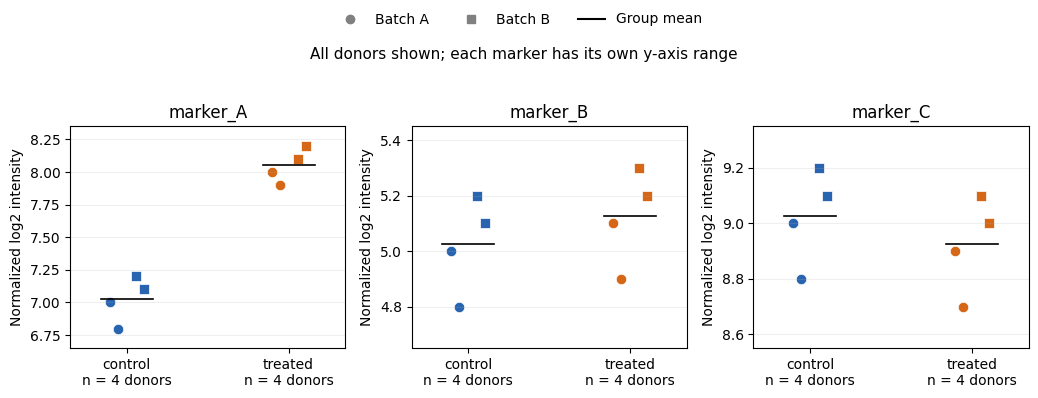

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, len(measurements), figsize=(10.4, 4.0))
colors = {'control': '#2864B0', 'treated': '#D56716'}
shapes = {'A': 'o', 'B': 's'}
for ax, feature in zip(axes, measurements.index):
    part = long_values.loc[long_values.feature_id == feature]
    for condition_no, condition in enumerate(['control', 'treated']):
        for batch, offset in [('A', -0.08), ('B', 0.08)]:
            values = part.loc[(part.condition == condition) & (part.batch == batch)].sort_values('sample_id')
            x = condition_no + offset + np.linspace(-0.025, 0.025, len(values))
            ax.scatter(x, values.log2_intensity, color=colors[condition], marker=shapes[batch], s=56, edgecolors='white', linewidths=0.5)
        mean_value = part.loc[part.condition == condition, 'log2_intensity'].mean()
        ax.plot([condition_no - 0.16, condition_no + 0.16], [mean_value, mean_value], color='black', linewidth=1.2)
    ax.set_title(feature)
    ax.set_xticks([0, 1], ['control\nn = 4 donors', 'treated\nn = 4 donors'])
    ax.set_xlim(-0.35, 1.35)
    ax.set_ylim(part.log2_intensity.min() - 0.15, part.log2_intensity.max() + 0.15)
    ax.grid(axis='y', alpha=0.2)
    ax.set_ylabel('Normalized log2 intensity')
handles = [Line2D([0], [0], marker=shape, color='gray', linestyle='', label='Batch ' + batch) for batch, shape in shapes.items()]
handles.append(Line2D([0], [0], color='black', label='Group mean'))
fig.legend(handles=handles, loc='upper center', ncol=3, frameon=False)
fig.suptitle('All donors shown; each marker has its own y-axis range', y=0.89, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.86))
figure_path = Path.cwd() / 'results/marker_distributions.png'
fig.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()


**관찰과 해석:** marker_A의 control 범위 6.8–7.2와 treated 범위 7.9–8.2는 겹치지 않는다. marker_B와 C에서는 조건별 범위가 겹친다. 배치 B 평균은 A보다 세 marker 모두 높다. marker_A의 배치별 treated-control 차이는 +1.05와 +1.00이고, B는 두 배치 모두 +0.10, C는 두 배치 모두 −0.10이다.

**다음 결정:** 배치 이동이 보이고 두 조건에 배치가 균형 있게 포함되어 있으므로 `log2 intensity ~ intercept + treated + batch_B` 가법 선형모형으로 조건 차이와 구간을 요약한다. 이 선택은 분포 확인 뒤 구체화한 탐색적 선택이다. 실패 기록은 없으며 어느 표본도 제외하지 않는다. 단 3개 marker의 분포로 일반적인 QC나 모형 가정을 충분히 검증할 수는 없다.

## 4. 배치를 반영한 treated-control 차이는 얼마나 큰가?

조건 계수는 동일 배치를 기준으로 한 **treated − control**의 평균 차이이며 단위는 log2 intensity이다. 배치 계수는 조건을 고려한 B − A 차이이다. 각 조건의 독립 n은 4명이다. 최소제곱으로 세 계수를 추정하고 잔차 자유도 5의 t 분포를 이용해 각 marker의 95% 신뢰구간을 계산한다. 구간은 독립 기증자, 가법성, 동일분산 정규오차 가정을 전제로 하며 n=8에서 그 가정을 확증할 수 없다.

목적은 3개 marker의 탐색적 차이와 불확실성을 요약하는 것이다. p값·유의성 순위·다중검정은 계산하지 않는다. **각 95% 구간은 다중비교를 보정한 동시 구간이 아니다.** 정규화된 intensity 차이를 절대 분자량 변화나 실제 생물학적 fold change로 확대 해석하지 않는다.

In [6]:
from scipy import stats

assert metadata.donor_id.is_unique, '독립 표본 가정이 바뀌었습니다.'
assert np.linalg.matrix_rank(design) == design.shape[1], '조건과 배치 계수가 식별되지 않습니다.'
X = design.to_numpy()

Y = measurements.to_numpy().T
coefficients = np.linalg.lstsq(X, Y, rcond=None)[0]
residuals = Y - X @ coefficients
degrees_freedom = len(metadata) - X.shape[1]
residual_variance = (residuals ** 2).sum(axis=0) / degrees_freedom
condition_se = np.sqrt(np.linalg.inv(X.T @ X)[1, 1] * residual_variance)
critical_t = stats.t.ppf(0.975, degrees_freedom)
control_mean = Y[metadata.condition == 'control'].mean(axis=0)
treated_mean = Y[metadata.condition == 'treated'].mean(axis=0)
effects = pd.DataFrame({
    'feature_id': measurements.index,
    'n_control_donors': int((metadata.condition == 'control').sum()),
    'n_treated_donors': int((metadata.condition == 'treated').sum()),
    'control_mean': control_mean, 'treated_mean': treated_mean,
    'unadjusted_difference': treated_mean - control_mean,
    'batch_adjusted_difference': coefficients[1],
    'ci95_low': coefficients[1] - critical_t * condition_se,
    'ci95_high': coefficients[1] + critical_t * condition_se,
    'batch_B_minus_A': coefficients[2],
    'residual_df': degrees_freedom,
})


In [7]:
print('treated-control의 차이를 log2 intensity 단위로 요약합니다. 95% 구간은 배치 가법 선형모형의 개별 marker 구간이며 동시 구간이 아닙니다.')
display(effects.set_index('feature_id')[['control_mean', 'treated_mean', 'batch_adjusted_difference', 'ci95_low', 'ci95_high', 'batch_B_minus_A']].round(4))
print('\n잔차 범위를 확인합니다. 각 marker에 관측치가 8개뿐이므로 정규성이나 동일 분산을 검증했다고 해석하지 않습니다.')
print(pd.DataFrame({'feature_id': measurements.index, 'residual_min': residuals.min(axis=0), 'residual_max': residuals.max(axis=0), 'residual_sd': np.sqrt(residual_variance)}).round(4).to_string(index=False))
effects.to_csv('results/treated_control_summary.tsv', sep='\t', index=False)


treated-control의 차이를 log2 intensity 단위로 요약합니다. 95% 구간은 배치 가법 선형모형의 개별 marker 구간이며 동시 구간이 아닙니다.


,control_mean,treated_mean,batch_adjusted_difference,ci95_low,ci95_high,batch_B_minus_A
feature_id,,,,,,
marker_A,7.025,8.050,1.025,0.8702,1.1798,0.225
marker_B,5.025,5.125,0.100,-0.0818,0.2818,0.250
marker_C,9.025,8.925,-0.100,-0.2818,0.0818,0.250



잔차 범위를 확인합니다. 각 marker에 관측치가 8개뿐이므로 정규성이나 동일 분산을 검증했다고 해석하지 않습니다.
feature_id  residual_min  residual_max  residual_sd
  marker_A       -0.1125        0.0875       0.0851
  marker_B       -0.1000        0.1000       0.1000
  marker_C       -0.1000        0.1000       0.1000


**관찰:** marker_A 차이는 +1.025 [0.870, 1.180], B는 +0.100 [−0.082, 0.282], C는 −0.100 [−0.282, 0.082]이다(대괄호는 개별 marker의 모형 기반 95% 구간, 모두 log2 intensity). 균형 설계이므로 보정 전·후 조건 차이는 같다. 배치 B − A 계수는 A에서 +0.225, B·C에서 +0.250이다.

**해석과 한계:** 이 합성 예시에서 marker_A는 큰 양의 차이를 보인다. B·C의 구간은 0을 포함해 방향이나 효과 부재를 확정할 수 없다. 잔차 범위가 작다는 사실만으로 정규성·동일분산을 확인할 수는 없다. 현 자료에서 더 점검할 수 있는 불확실성은 특정 배치나 단일 기증자가 관측된 방향을 주도하는지이다. 이에 배치별 차이를 명시적으로 계산하고, 한 기증자씩 제외해 계수의 변화를 살펴본다. 이는 결과를 본 뒤 추가한 민감도 점검이며 최종 분석의 표본 제외 기준이 아니다.

## 5. 특정 배치나 기증자 한 명이 차이를 주도하는가?

먼저 각 배치 안의 treated-control 평균 차이를 계산한다. 각 조건·배치에는 2명만 있으므로 배치 간 차이가 작더라도 조건×배치 상호작용이 없다고 입증할 수는 없다. 이어 8명의 기증자를 각각 한 번씩 제외하고 매번 배치 가법 모형을 다시 적합한다. 표의 min·max는 그 8개 계수의 범위이며 신뢰구간이나 독립 검증이 아니다. 각 민감도 시나리오는 7명으로 계산하고 본 분석은 8명을 모두 유지한다.

In [8]:
batch_rows = []
for batch in ['A', 'B']:
    control_rows = (metadata.batch == batch) & (metadata.condition == 'control')
    treated_rows = (metadata.batch == batch) & (metadata.condition == 'treated')
    differences = Y[treated_rows].mean(axis=0) - Y[control_rows].mean(axis=0)
    for feature, difference in zip(measurements.index, differences):
        batch_rows.append({'feature_id': feature, 'batch': batch, 'n_control_donors': int(control_rows.sum()), 'n_treated_donors': int(treated_rows.sum()), 'treated_minus_control': difference})
batch_effects = pd.DataFrame(batch_rows)
print('배치별 조건 차이가 같은 방향인지 확인합니다. 각 배치 안에는 조건당 2명뿐이므로 상호작용의 부재를 입증하는 검정은 아닙니다.')
print(batch_effects.round(4).to_string(index=False))


배치별 조건 차이가 같은 방향인지 확인합니다. 각 배치 안에는 조건당 2명뿐이므로 상호작용의 부재를 입증하는 검정은 아닙니다.
feature_id batch  n_control_donors  n_treated_donors  treated_minus_control
  marker_A     A                 2                 2                   1.05
  marker_B     A                 2                 2                   0.10
  marker_C     A                 2                 2                  -0.10
  marker_A     B                 2                 2                   1.00
  marker_B     B                 2                 2                   0.10
  marker_C     B                 2                 2                  -0.10


In [9]:
leave_one_out_rows = []
for omitted in range(len(metadata)):
    keep = np.arange(len(metadata)) != omitted
    assert np.linalg.matrix_rank(X[keep]) == X.shape[1], '표본 제거 후 설계가 식별되지 않습니다.'
    reduced_coefficients = np.linalg.lstsq(X[keep], Y[keep], rcond=None)[0]
    for feature, coefficient in zip(measurements.index, reduced_coefficients[1]):
        leave_one_out_rows.append({'feature_id': feature, 'omitted_sample': metadata.loc[omitted, 'sample_id'], 'omitted_donor': metadata.loc[omitted, 'donor_id'], 'batch_adjusted_difference': coefficient})
leave_one_out = pd.DataFrame(leave_one_out_rows)
sensitivity = leave_one_out.groupby('feature_id').batch_adjusted_difference.agg(['min', 'max'])
print('\n기증자 1명씩 제외하고 가법 모형을 다시 계산한 조건 차이의 범위입니다. 이 범위는 신뢰구간이 아니며 본 분석에서는 아무 표본도 제외하지 않습니다.')
print(sensitivity.round(4).to_string())
print('계산한 민감도 시나리오:', leave_one_out.omitted_donor.nunique(), '(각 7명)')
batch_effects.to_csv('results/batch_stratified_differences.tsv', sep='\t', index=False)
leave_one_out.to_csv('results/leave_one_donor_out.tsv', sep='\t', index=False)



기증자 1명씩 제외하고 가법 모형을 다시 계산한 조건 차이의 범위입니다. 이 범위는 신뢰구간이 아니며 본 분석에서는 아무 표본도 제외하지 않습니다.
             min   max
feature_id            
marker_A    0.98  1.06
marker_B    0.06  0.14
marker_C   -0.14 -0.06
계산한 민감도 시나리오: 8 (각 7명)


**관찰과 판단:** marker_A의 배치별 차이는 A +1.05 / B +1.00, B는 +0.10 / +0.10, C는 −0.10 / −0.10이다. 기증자 한 명씩 제외한 계수 범위는 A +0.980–+1.060, B +0.060–+0.140, C −0.140–−0.060으로, 8개 시나리오 모두 원래 방향을 유지했다. 이 점검에서는 하나의 배치나 기증자만으로 방향이 만들어진 징후를 보지 못했다. 하지만 B·C의 방향 안정성과 95% 구간이 0을 포함한다는 사실은 서로 다른 질문에 대한 결과이며 함께 보존해야 한다.

**현재 자료에서 완료한 다음 점검:** 배치별 비교와 기증자 1명 제외 민감도 분석. 이 자료 안에서 더 반복 분석해 실제 생물학적 결론을 강화할 근거는 없다. 실제 연구로 이어간다면 새로운 독립 기증자를 배치·조건별로 확보하고, 조건 배정·정규화 기록 및 사전 효과 크기 기준을 확인해야 한다. 이는 새로운 실험의 배치 일반화와 측정 해석 불확실성을 줄이기 위한 제안이며 수행한 작업이 아니다.

## 실행·보존 기록

아래 기록은 입력 파일의 SHA256(정확한 파일 내용의 식별값), 주요 패키지 버전, 처리 전후 규모와 검증 상태를 저장한다. 입력 파일의 실행 전후 내용이 같은지 검사한다. 이 검사는 원본 보존과 실행 재현성을 확인하며 생물학적 검증은 아니다.

탐색 중 민감도 코드에서 ID 정렬 후 인덱스 이름이 사라져 `sample_id`를 찾지 못하는 오류가 한 번 발생했다. ID 이름을 명시해 수정하고 전체 민감도 계산을 다시 수행했다. 모형과 입력 값은 변경하지 않았다. 최종 노트북은 이름을 보존한 ID 연결을 사용한다. 스크립트의 비대화형 그림 표시 경고는 PNG 저장을 막지 않았고 저장한 그림을 직접 열어 범례·축·24개 점의 표시를 점검했다.

In [10]:
import json
import sys
import scipy
import matplotlib
import nbformat
import nbclient
from datetime import datetime, timezone

final_hashes = {name: hashlib.sha256((root / name).read_bytes()).hexdigest() for name in input_names}
assert input_hashes == final_hashes, '실행 중 입력 파일 내용이 바뀌었습니다.'
provenance = {
    'timestamp_utc': datetime.now(timezone.utc).isoformat(),
    'inputs_sha256': input_hashes,
    'versions': {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__, 'nbformat': nbformat.__version__, 'nbclient': nbclient.__version__},
    'contrast': 'treated - control', 'model': 'intercept + treated + batch_B',
    'before': {'donors': 8, 'samples': 8, 'features': 3, 'values': 24},
    'after': {'donors': len(metadata), 'samples': measurements.shape[1], 'features': measurements.shape[0], 'values': measurements.size},
    'excluded_samples': [], 'excluded_features': [], 'randomness': 'none',
    'pointwise_ci_level': 0.95, 'multiple_testing': 'no p values; CIs are not simultaneous',
    'input_contents_unchanged_during_execution': input_hashes == final_hashes,
}
(root / 'results/provenance.json').write_text(json.dumps(provenance, ensure_ascii=False, indent=2))
print('재실행 환경과 원본 보존을 기록합니다. 입력 3개의 실행 전후 SHA256은 모두 일치합니다.')
print(pd.Series(provenance['versions']).to_string())

재실행 환경과 원본 보존을 기록합니다. 입력 3개의 실행 전후 SHA256은 모두 일치합니다.
python        3.12.7
numpy          2.1.3
pandas         2.3.1
scipy         1.16.0
matplotlib    3.10.8
nbformat      5.10.4
nbclient      0.10.2


## 짧은 결과 기록

표본 8개와 marker 3개를 모두 유지했고 ID 불일치·중복·결측은 없었다. control/treated는 독립 기증자 각 4명이며 각 조건에 배치 A·B가 2명씩 있다. 배치 보정 treated-control 차이는 marker_A **+1.025** (95% 구간 **0.870–1.180**), marker_B **+0.100** (**−0.082–0.282**), marker_C **−0.100** (**−0.282–0.082**) log2 intensity이다. 배치별 차이와 기증자 1명 제외 분석에서 방향은 유지되었다. 작은 합성 자료이며 구간은 모형 가정에 의존하는 개별 구간이다. B·C에서 효과 부재를 입증하지 않았고 실제 생물학적 검증은 수행하지 않았다.

근거 표는 `results/treated_control_summary.tsv`, `results/batch_stratified_differences.tsv`, `results/leave_one_donor_out.tsv`에, 그림은 `results/marker_distributions.png`에 있다. 원본 식별값과 환경은 `results/provenance.json`에 기록한다. 새 커널 전체 실행 여부와 코드 셀 오류 수는 노트북을 실행하는 `run_analysis.py`가 `results/execution.json`에 기록한다. 파일 생성·실행 성공과 그림 직접 열람은 서로 다른 확인이며, 그림은 최종 재실행 뒤에도 직접 확인한다.

**2026-10-21 완성본 검증:** 새 커널에서 코드 셀 10개를 1–10 순서로 모두 실행했으며 오류 출력은 0개였다. 저장된 표·수치를 읽어 위 해석과 대조했다. 원본 입력 3개의 실행 전후 SHA256이 일치한다. 최종 PNG를 원본 해상도로 직접 열어 3개 패널의 축·범례·24개 관측점이 잘리지 않고 표시되는 것을 확인했다. 이는 실행·보존·표시 확인이며 실제 생물학적 검증은 아니다.